# Porter: Delivery Time Estimation using Neural Networks

**Section 3 of 5 (20 marks): Data Visualization, Outlier Detection and Cleaning**

| Section | Topic | Marks | File |
|:--:|:--|:--:|:--|
| 1 | Problem Statement, Data Import and Data Structure Analysis | 10 | [open](section_1_problem_and_data.ipynb) |
| 2 | Data Preprocessing and Feature Engineering | 30 | [open](section_2_preprocessing.ipynb) |
| 3 | Data Visualization, Outlier Detection and Cleaning | 20 | **you are here** |
| 4 | Model Training with Random Forest | 10 | [open](section_4_random_forest.ipynb) |
| 5 | Regression with Neural Networks | 30 | [open](section_5_neural_network.ipynb) |

**Note.** This notebook continues from [section_2_preprocessing.ipynb](section_2_preprocessing.ipynb): it uses the data, variables and functions created in the earlier sections, and the outputs below were saved from one full run of the whole case study. To run the code again, run the cells in order from Section 1 (use `../solution.ipynb` to do this in one go).

<a id="sec3"></a>

# Section 3: Data Visualization, Outlier Detection and Cleaning (20 points)

### Objective and Tasks of this Section

**Stage 3 of 5 · 6 Tasks: Data Visualization, Outlier Detection & Cleaning**

**Objective:** You will visualize relationships in the cleaned data, understand why outliers matter, detect and remove them, and confirm visually that the cleaning improved the data.

| Task | What to do | Hint |
|:--|:--|:--|
| **Task 3.1** | Visualize relationships between the target and key features — for example a correlation heatmap and scatterplots of time_taken_mins against subtotal, and total_items against subtotal. | Think about which plot type best shows the correlation strength between many numeric columns at once, versus which best shows the relationship between two specific variables. |
| **Task 3.2** | Explain why it's important to check for outliers before training a model on this data. | Think about how a small number of extreme delivery times could disproportionately pull a regression model's error metric or its learned relationships. |
| **Task 3.3** | Name three methods that can be used to detect or remove outliers. | Think about a simple statistical rule based on quartiles, a plot-based visual method, and a model-based method that scores each point relative to its neighbors. |
| **Task 3.4** | Apply an outlier detection method to the data, print how many rows were flagged, and remove those rows. | Think about a method that can flag unusual rows across several columns at once, rather than looking at just one column in isolation. |
| **Task 3.5** | Re-plot the same scatterplot from Task 3.1 after removing outliers, and compare it to the original to confirm the cleaning helped. | Think about which exact plot you produced before cleaning — reusing it after cleaning is the only way to see whether the distribution actually improved. |
| **Task 3.6** | Visualize order volume by day of week and hour of day, and check whether time of day affects delivery time. | Think about which plot best shows a count/frequency by category, versus which best shows a trend across a continuous-like feature such as hour. |

**Evaluation criteria of this section (20 points):**

| Criterion | Done in |
|:--|:--|
| Visualization for various features | 3.1, 3.6 |
| Check for outliers | 3.1 to 3.3 |
| Remove outliers | 3.4 |
| Compare plots and results | 3.5 |

Each task below is marked in its heading, for example `(Task 3.1)`.

---


Now that the data is clean and complete, we look at it with charts (countplots and scatterplots, as in the brief), check for outliers, remove them, and plot the data again to see whether anything improved.

**Flow of this section:**

```
Countplots & scatterplots --> Why outliers matter --> Three methods --> Detect & remove --> Compare --> Day & hour patterns
```

## 3.1 Visualising the Data (Task 3.1)

We import `IsolationForest`, which we use in Section 3.4, and list the eight numeric columns that describe the order and the partner supply.

In [38]:
from sklearn.ensemble import IsolationForest

num_cols = ["total_items", "subtotal", "num_distinct_items", "min_item_price", "max_item_price",
            "total_onshift_dashers", "total_busy_dashers", "total_outstanding_orders"]

day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

### Countplots of the Categorical Columns

A countplot shows how many orders fall into each category.

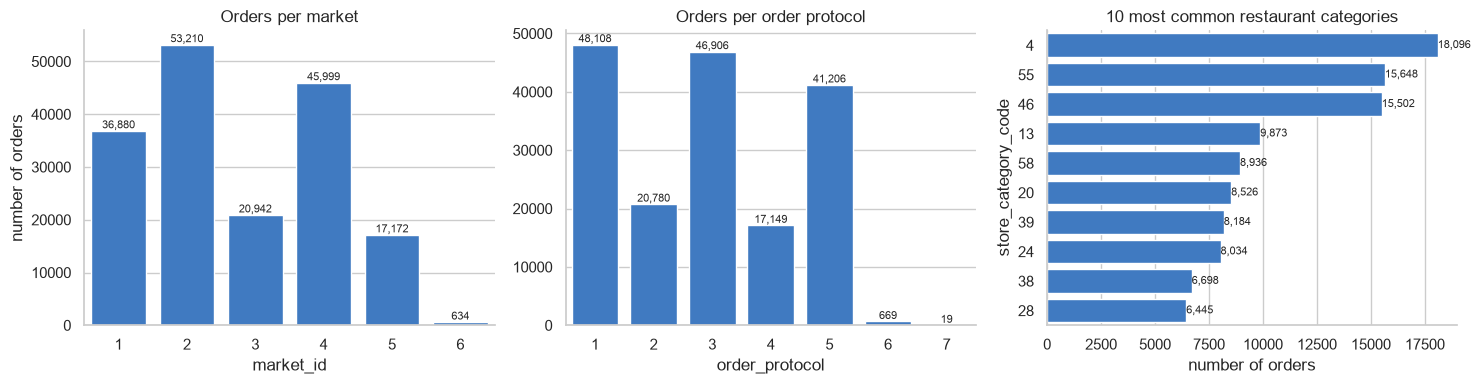

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(data=df, x="market_id", color=BLUE, ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt="{:,.0f}", fontsize=8)
axes[0].set_title("Orders per market")
axes[0].set_ylabel("number of orders")

sns.countplot(data=df, x="order_protocol", color=BLUE, ax=axes[1])
axes[1].bar_label(axes[1].containers[0], fmt="{:,.0f}", fontsize=8)
axes[1].set_title("Orders per order protocol")
axes[1].set_ylabel("")

top_codes = df["store_category_code"].value_counts().head(10).index
sns.countplot(data=df, y="store_category_code", order=top_codes, color=BLUE, ax=axes[2])
axes[2].bar_label(axes[2].containers[0], fmt="{:,.0f}", fontsize=8)
axes[2].set_title("10 most common restaurant categories")
axes[2].set_xlabel("number of orders")

plt.tight_layout()
plt.show()

From the charts, market 2 has the most orders (53,210) and market 6 almost none (634). Order protocols 1, 3 and 5 carry most of the orders, while protocols 6 and 7 are rare (669 and 19 orders). A few restaurant categories (4, 55 and 46) account for far more orders than the rest.

### Histograms of the Numeric Columns

A histogram shows how the values of one column are spread. We use a log scale on the vertical axis so that rare, extreme values stay visible next to the very common small ones.

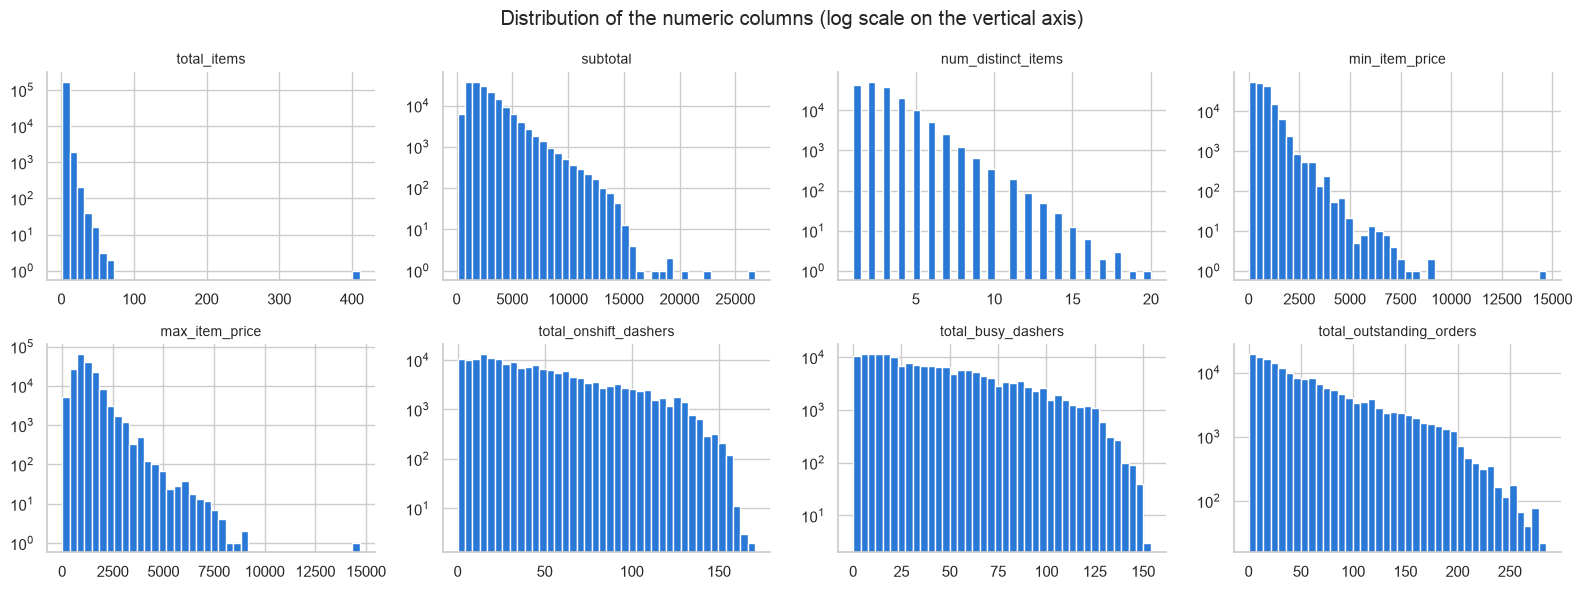

In [40]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.ravel(), num_cols):
    ax.hist(df[col], bins=40, color=BLUE, log=True)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Distribution of the numeric columns (log scale on the vertical axis)")
plt.tight_layout()
plt.show()

From the histograms, every column has most of its values at the low end and a thin tail to the right, and the log scale makes the single rows in those tails visible. `total_items` has almost all orders below about 20 items, yet one order has 411; `subtotal` stretches to 26,800 and the two item-price columns to about 14,700, each with only a handful of rows far out. `num_distinct_items` thins out steadily up to 20. The three partner columns are spread more evenly and only thin out above about 125 to 150, while the number of orders waiting falls off steadily towards 280. This long-tailed shape is why the outlier check in 3.2 to 3.4 matters.

### Correlation Heatmap

`df.corr()` measures how strongly each pair of numeric columns moves together, from -1 to +1. `sns.heatmap` draws it with the numbers printed inside. The colours run from blue (negative) through grey (zero) to orange (positive).

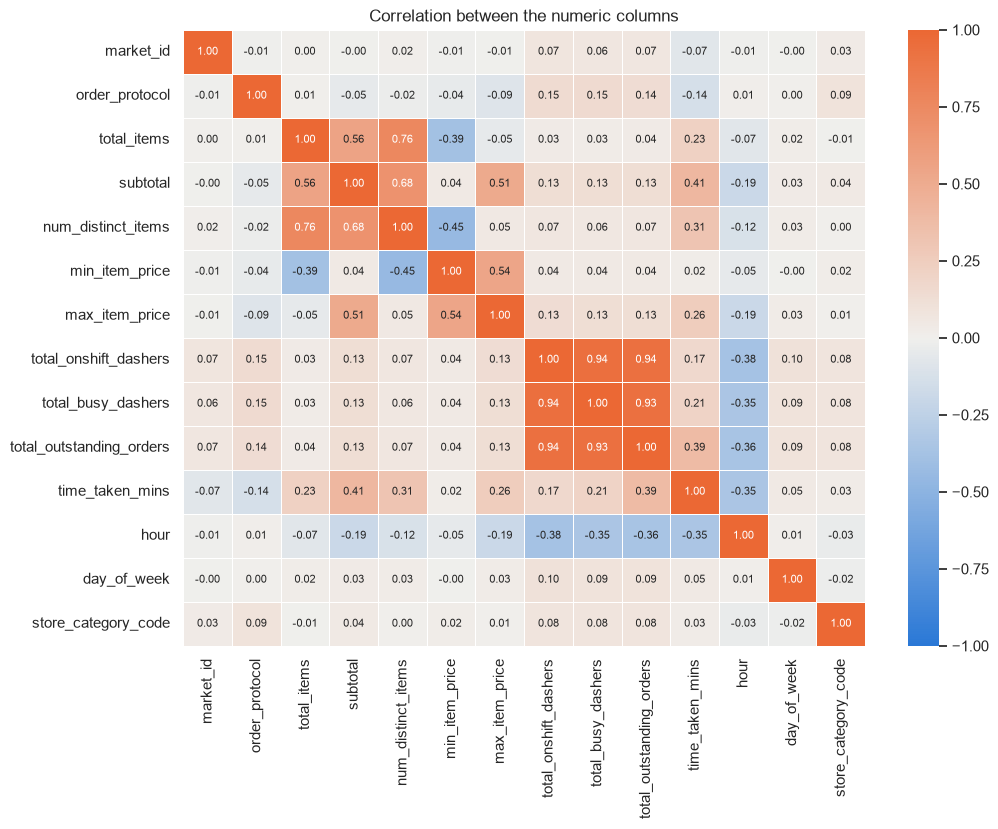

In [41]:
DIVERGING = sns.blend_palette([BLUE, "#f0efec", ORANGE], as_cmap=True)

plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap=DIVERGING, vmin=-1, vmax=1,
            annot_kws={"size": 8}, linewidths=0.5, linecolor="white")
plt.title("Correlation between the numeric columns")
plt.show()

In [42]:
df.corr(numeric_only=True)["time_taken_mins"].sort_values(ascending=False).round(2)

time_taken_mins             1.00
subtotal                    0.41
total_outstanding_orders    0.39
num_distinct_items          0.31
max_item_price              0.26
total_items                 0.23
total_busy_dashers          0.21
total_onshift_dashers       0.17
day_of_week                 0.05
store_category_code         0.03
min_item_price              0.02
market_id                  -0.07
order_protocol             -0.14
hour                       -0.35
Name: time_taken_mins, dtype: float64

From the heatmap, delivery time is most strongly related to `subtotal` (0.41), `total_outstanding_orders` (0.39) and `hour` (-0.35: orders placed at later hours are faster), followed by `num_distinct_items` (0.31). The three supply columns (partners on shift, busy partners, orders waiting) carry almost the same signal, with correlations of 0.93 to 0.94 between them, and `total_items` and `num_distinct_items` also move together (0.76). `store_category_code` (0.03) and `day_of_week` (0.05) show almost no straight-line relation to delivery time, although a model can still use them in other ways.

### Scatterplots (Before Removing Outliers)

We plot delivery time against subtotal, and total items against subtotal. We define the plots as a function, so that exactly the same plot can be drawn again after the outliers are removed. A random sample of 20000 orders keeps the plot readable.

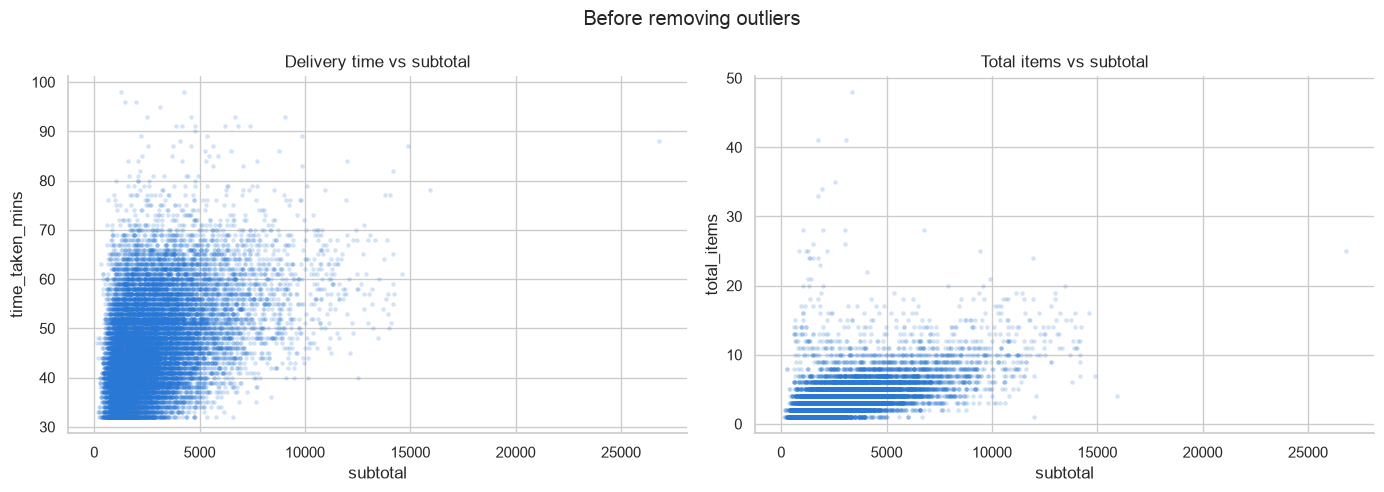

In [43]:
def scatter_pair(data, title):
    sample = data.sample(20000, random_state=42)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.scatterplot(data=sample, x="subtotal", y="time_taken_mins", s=8, alpha=0.2, color=BLUE, edgecolor=None, ax=axes[0])
    axes[0].set_title("Delivery time vs subtotal")
    sns.scatterplot(data=sample, x="subtotal", y="total_items", s=8, alpha=0.2, color=BLUE, edgecolor=None, ax=axes[1])
    axes[1].set_title("Total items vs subtotal")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

scatter_pair(df, "Before removing outliers")

From the scatterplots, delivery time rises with subtotal, but the cloud is wide: orders of the same size take anywhere from 32 to about 100 minutes, so subtotal alone cannot predict delivery time. A few orders sit far to the right (one near 27,000), and in the second plot almost all orders have fewer than 20 items, with a handful of points far above.

### Box Plots to Check for Outliers (Before Removing Outliers)

A box plot shows the middle half of the values as a box and marks the unusual values as dots. Each column has its own scale.

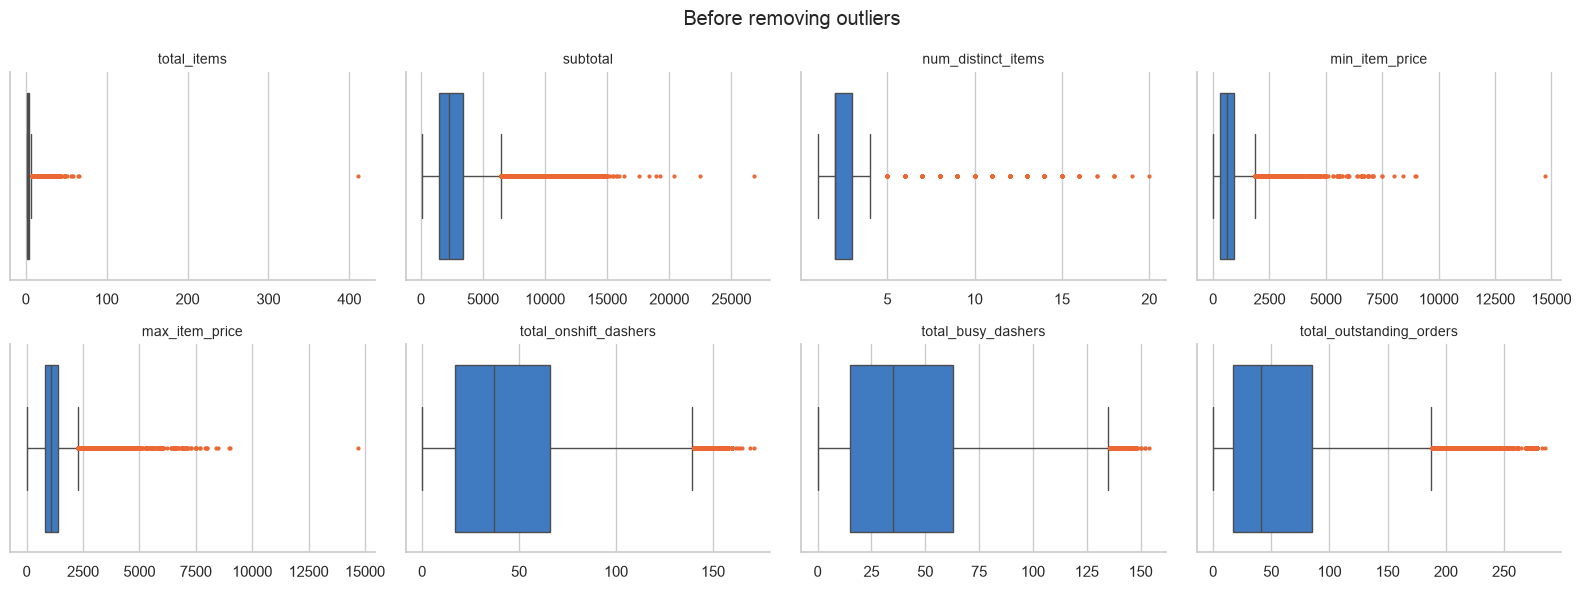

In [44]:
def box_grid(data, title):
    fig, axes = plt.subplots(2, 4, figsize=(16, 6))
    for ax, col in zip(axes.ravel(), num_cols):
        sns.boxplot(x=data[col], color=BLUE, fliersize=2, flierprops={"markerfacecolor": ORANGE, "markeredgecolor": ORANGE}, ax=ax)
        ax.set_title(col, fontsize=10)
        ax.set_xlabel("")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

box_grid(df, "Before removing outliers")

From the box plots, every column has orange dots beyond its whiskers on the right side. `total_items` has one order of 411 items, far away from everything else. `subtotal` and the two item-price columns have long tails of expensive orders, and the three partner columns have dots at the busiest moments. These are the values the rest of this section examines.

## 3.2 Why Check for Outliers? (Task 3.2, Brief Question 4)

> **Brief Question 4:** *Why do we need to check for outliers in our data?*


An **outlier** is a value that sits far away from the rest of the data. We check for them before training because:

- **Averages and spreads get pulled.** One order with 411 items moves the mean and the standard deviation of `total_items`, and `StandardScaler` uses both.
- **Squared errors reward big values.** The mean squared error squares every mistake, so a few extreme rows can dominate the loss and drag the weights of a neural network towards them.
- **Models learn from too little evidence.** A very rare kind of order has so few examples that the model cannot learn it, but it can still distort the rest.
- **They may be mistakes.** Some outliers are typing or system errors that should not be learned at all.

**Note:** An outlier is not automatically wrong. A very large order can be real. So we look at the outliers first, and then decide what to do with them.

## 3.3 Three Methods to Find and Remove Outliers (Task 3.3, Brief Question 5)

> **Brief Question 5:** *Name 3 outlier removal methods?*


| Method | How it works | Looks at |
|:--|:--|:--|
| **IQR rule** (the rule behind a box plot) | A value is an outlier if it is more than 1.5 times the IQR (the width of the middle half) below the first quartile or above the third quartile | One column at a time |
| **Z-score** | A value is an outlier if it is more than 3 standard deviations from the mean | One column at a time |
| **Box plot or scatterplot** (visual method) | Points beyond the whiskers of a box plot, or far away from the main cloud of a scatterplot, are outlier candidates. We drew both in Section 3.1 | One or two columns at a time |
| **Isolation Forest** (also Local Outlier Factor, DBSCAN) | Random trees try to isolate each row. Rows that are isolated with very few splits are unusual | Several columns at once |

The brief allows any method. We use **Isolation Forest** as the main method, because it looks at several columns together instead of one column in isolation. A multi-column method can miss a value that is extreme in only one column, so we add a simple one-column percentile rule after it (Section 3.4).

### How Many Rows Would Each Method Flag?

We apply all three methods to the cleaned data (nothing is removed yet) and count the rows that each one flags. The IQR rule and the z-score flag a row if **any** of the eight numeric columns is extreme. The Isolation Forest looks at the eight columns together.

In [45]:
q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
iqr = q3 - q1
iqr_flag = (df[num_cols] < q1 - 1.5 * iqr) | (df[num_cols] > q3 + 1.5 * iqr)
z_flag = ((df[num_cols] - df[num_cols].mean()) / df[num_cols].std()).abs() > 3
iso_flag = IsolationForest(n_estimators=100, contamination=0.01, random_state=42, n_jobs=-1).fit(df[num_cols]).predict(df[num_cols]) == -1

flag_table = pd.DataFrame({
    "rows flagged": [iqr_flag.any(axis=1).sum(), z_flag.any(axis=1).sum(), iso_flag.sum()],
    "share of the data (%)": [iqr_flag.any(axis=1).mean() * 100, z_flag.any(axis=1).mean() * 100, iso_flag.mean() * 100],
}, index=["IQR rule (any column)", "Z-score above 3 (any column)", "Isolation Forest (eight columns together)"])
flag_table.round(2)

,rows flagged,share of the data (%)
IQR rule (any column),36173,20.69
Z-score above 3 (any column),11222,6.42
Isolation Forest (eight columns together),1749,1.00


From the table, the choice of method changes the number of flagged rows enormously: the IQR rule flags 36,173 rows (20.7% of the data) and the z-score rule flags 11,222 rows (6.4%), while the Isolation Forest flags 1,749 rows (1.0%). The Isolation Forest flags exactly the share we ask for (`contamination=0.01`), whereas the other two decide the number from the data. Almost every column here is skewed to the right, and the IQR rule assumes a more even spread, so it would throw away a fifth of ordinary orders because one column is on the high side. That is why the Isolation Forest is our main method.

## 3.4 Detect and Remove Outliers (Task 3.4)

`contamination=0.01` tells the Isolation Forest to flag about 1% of the rows as the most unusual ones. We give it only the eight numeric input columns and **not** the delivery time, so the target does not decide which rows are removed.

In [46]:
df_before = df.copy()

iso = IsolationForest(n_estimators=100, contamination=0.01, random_state=42, n_jobs=-1)
iso.fit(df[num_cols])
df["is_outlier"] = iso.predict(df[num_cols]) == -1

print("Rows flagged as outliers:", df["is_outlier"].sum(), f"({df['is_outlier'].mean() * 100:.2f}% of the data)")

Rows flagged as outliers: 1749 (1.00% of the data)


The rows the Isolation Forest flagged, so that we can see what it considers unusual (the first ten are printed).

In [47]:
df[df["is_outlier"]][num_cols + ["time_taken_mins"]].head(10)

,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,time_taken_mins
12,7,14900,5,1200,3900,8.0,11.0,11.0,87.0
126,5,8450,5,950,2800,123.0,117.0,190.0,56.0
160,13,9980,10,100,1345,62.0,58.0,102.0,64.0
316,25,10286,14,280,495,41.0,34.0,40.0,53.0
512,7,9800,6,1200,2300,102.0,124.0,132.0,55.0
908,8,11600,7,500,3700,54.0,41.0,51.0,50.0
917,1,7475,1,7475,7475,15.0,14.0,14.0,54.0
1003,3,14700,3,3600,3600,38.0,37.0,38.0,56.0
1020,8,8860,8,795,995,136.0,81.0,137.0,49.0
1202,1,4592,1,4362,4509,18.0,17.0,10.0,38.0


Let's see what the flagged rows look like. In the charts they are drawn in orange.

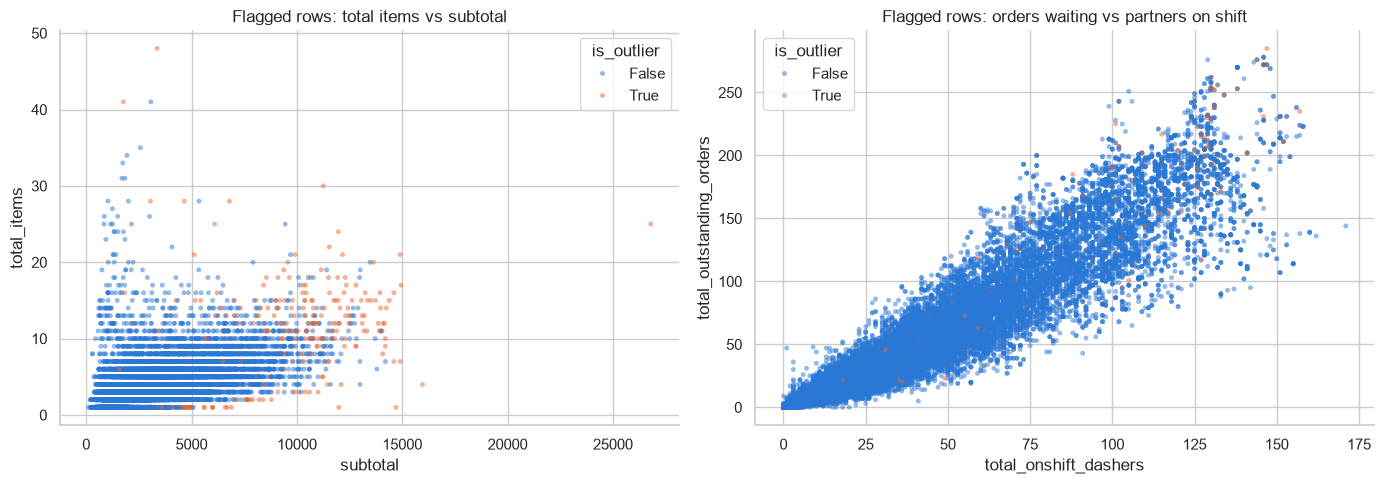

In [48]:
sample = df.sample(30000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=sample, x="subtotal", y="total_items", hue="is_outlier", palette={False: BLUE, True: ORANGE},
                s=10, alpha=0.5, edgecolor=None, ax=axes[0])
axes[0].set_title("Flagged rows: total items vs subtotal")
sns.scatterplot(data=sample, x="total_onshift_dashers", y="total_outstanding_orders", hue="is_outlier", palette={False: BLUE, True: ORANGE},
                s=10, alpha=0.5, edgecolor=None, ax=axes[1])
axes[1].set_title("Flagged rows: orders waiting vs partners on shift")
plt.tight_layout()
plt.show()

In [49]:
df.groupby("is_outlier")[num_cols + ["time_taken_mins"]].mean().T.round(1)

is_outlier,False,True
total_items,3.1,9.8
subtotal,2644.1,8516.6
num_distinct_items,2.6,6.7
min_item_price,677.1,1244.3
max_item_price,1149.3,2220.3
total_onshift_dashers,44.6,74.7
total_busy_dashers,41.6,69.9
total_outstanding_orders,57.7,112.1
time_taken_mins,46.1,60.0


From the output above, the Isolation Forest flagged 1,749 rows (1.00%), and 173,088 rows remain after removing them. The flagged orders are much bigger (average subtotal 8,517 against 2,644, and 9.8 items against 3.1) and were placed at busy moments (112 orders waiting against 58). Their average delivery time is 60 minutes against 46, even though delivery time was **not** given to the method, so the flagged rows are genuinely unusual deliveries and not a random 1%.

Now we remove the flagged rows.

In [50]:
df = df[~df["is_outlier"]].drop(columns="is_outlier").reset_index(drop=True)

print("Rows before:", len(df_before))
print("Rows after :", len(df))

Rows before: 174837
Rows after : 173088


### A Second, Simple Rule for One Extreme Column

The Isolation Forest judges all eight columns together, so an order that is extreme in **one** column but ordinary in the others can slip through. Let's check the largest item counts that are left.

In [51]:
df.sort_values("total_items", ascending=False)[["total_items", "subtotal", "num_distinct_items", "max_item_price", "time_taken_mins"]].head(8)

,total_items,subtotal,num_distinct_items,max_item_price,time_taken_mins
41285,411,3115,5,299,40.0
159933,66,1634,6,499,35.0
159929,64,1166,4,499,32.0
65866,59,2911,3,329,35.0
13092,57,858,5,229,32.0
9685,56,2317,7,289,37.0
92271,51,1343,4,169,43.0
111988,48,3786,7,435,34.0


One order has 411 items, and the next largest has only 66. This order has just 5 different items and a subtotal of about 3,100, which does not fit 411 items, so it is almost certainly a data entry error.

A rule such as the IQR fence (`Q3 + 1.5 x IQR`) would be too harsh here: the middle half of the orders has 2 to 4 items, so the fence is only 7 items and would remove thousands of ordinary larger orders. Instead we remove only the most extreme 0.1%: orders with more items than the **99.9th percentile** of `total_items`.

In [52]:
cap = df["total_items"].quantile(0.999)
extreme = df["total_items"] > cap

print(f"99.9th percentile of total_items: {cap:.1f}")
print(f"Rows above it: {extreme.sum()} ({extreme.mean() * 100:.2f}% of the data)")
print(f"Average delivery time of these rows: {df.loc[extreme, 'time_taken_mins'].mean():.1f} minutes (all rows: {df['time_taken_mins'].mean():.1f})")

df = df[~extreme].reset_index(drop=True)
print("Rows after the second rule:", len(df))

99.9th percentile of total_items: 21.9
Rows above it: 174 (0.10% of the data)
Average delivery time of these rows: 42.7 minutes (all rows: 46.1)
Rows after the second rule: 172914


**Note on the order of the steps:** the brief cleans the data before splitting it, so the outlier rules (including the 99.9th percentile) were worked out on all rows, also on rows that later land in the test set. Only input columns were used, never the target, so the effect is small, but it is a mild form of leakage. In a live system the rules would be fitted on the training rows only and then applied unchanged to new orders.

From the output above, the largest item counts are 411, then 66, 64, 59 and so on: the 411-item order is far away from everything else. The 99.9th percentile of `total_items` is 21.9, and 174 rows (0.10%) are above it, so 172,914 rows remain. These rows are not slower than normal orders (42.7 minutes on average against 46.1 for all rows), so removing them does not throw away the slowest deliveries.

## 3.5 Compare the Plots and Results Before and After (Task 3.5)

We draw exactly the same scatterplots and box plots again and compare them with the earlier ones.

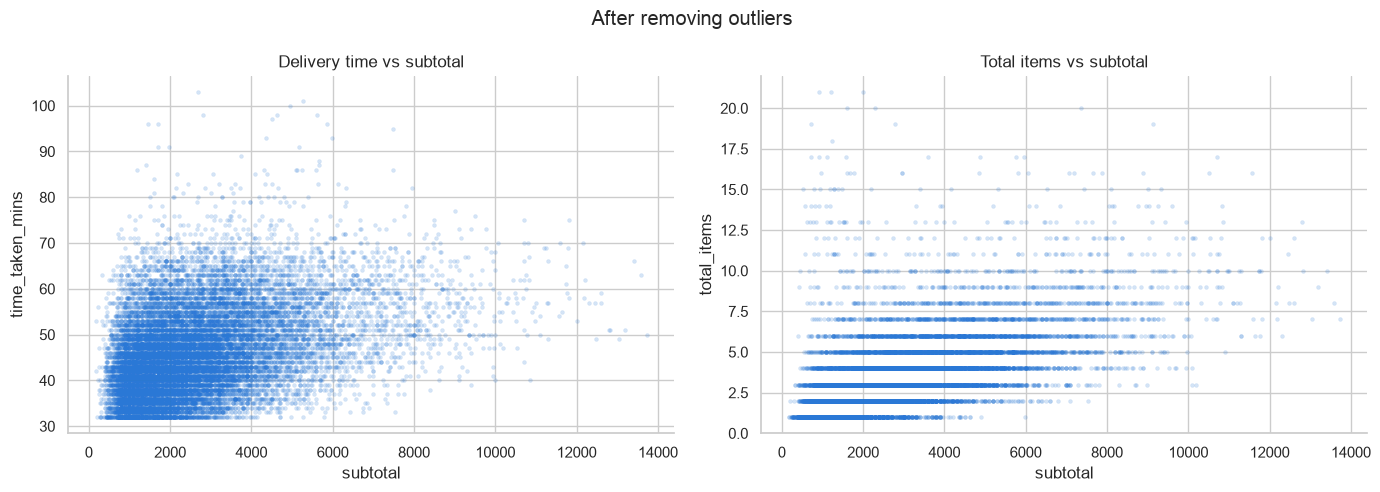

In [53]:
scatter_pair(df, "After removing outliers")

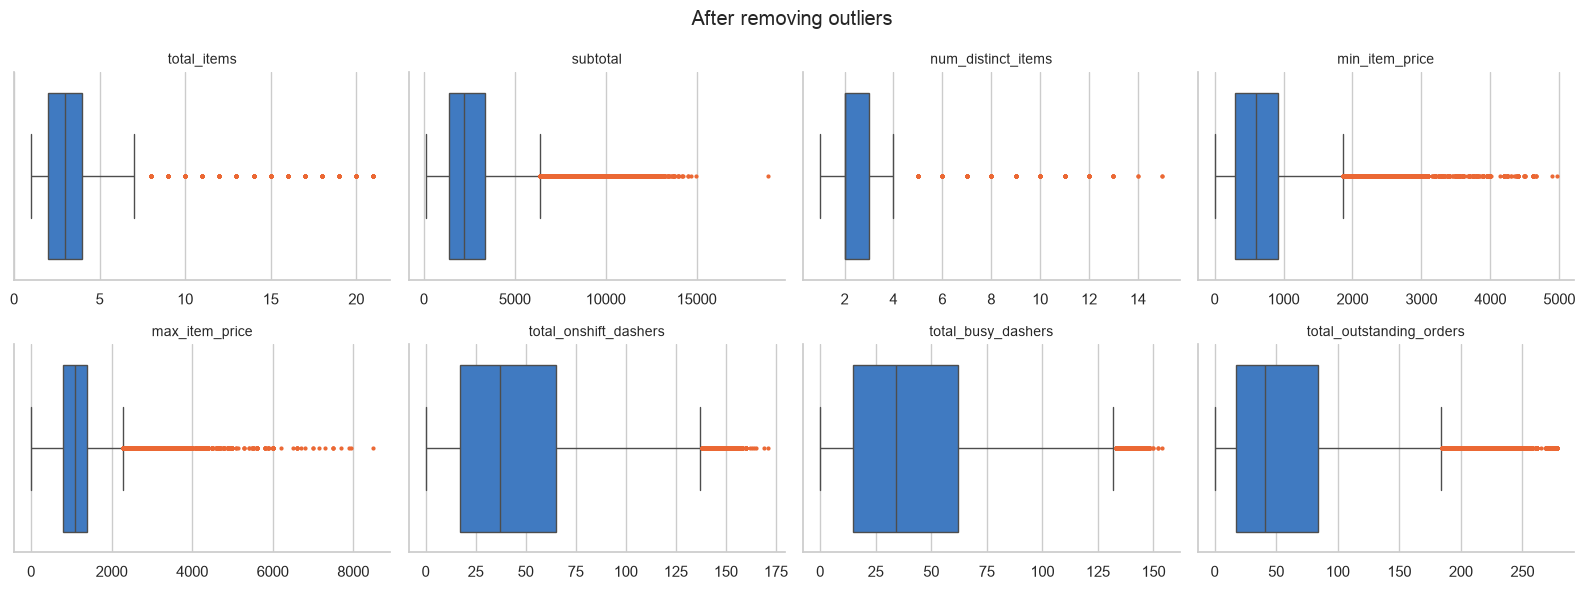

In [54]:
box_grid(df, "After removing outliers")

The numbers tell the same story:

In [55]:
def summary(data):
    return pd.Series({
        "rows": len(data),
        "max total_items": data["total_items"].max(),
        "max subtotal": data["subtotal"].max(),
        "max total_outstanding_orders": data["total_outstanding_orders"].max(),
        "std of subtotal": data["subtotal"].std(),
        "std of delivery time": data["time_taken_mins"].std(),
        "corr(time, subtotal)": data["time_taken_mins"].corr(data["subtotal"]),
    })

pd.DataFrame({"before": summary(df_before), "after": summary(df)}).round(2)

,before,after
rows,174837.00,172914.00
max total_items,411.00,21.00
max subtotal,26800.00,18920.00
max total_outstanding_orders,285.00,278.00
std of subtotal,1829.61,1703.35
std of delivery time,9.33,9.23
"corr(time, subtotal)",0.41,0.40


From the output above, after both steps 172,914 rows remain: 1,923 fewer than before (1,749 from the Isolation Forest and 174 from the percentile rule), which is 1.1% of the data. The largest subtotal fell from 26,800 to 18,920, the largest item count from 411 to 21 and the largest number of waiting orders from 285 to 278. The spread of subtotal fell from 1,830 to 1,703 and the spread of delivery time from 9.33 to 9.23, and the correlation between delivery time and subtotal barely changed (0.41 to 0.40).

So the cleaning removed the extreme rows and left the main relationships alone: the "after" scatterplot of items against subtotal is no longer stretched by a single 411-item order, and the cloud of delivery time against subtotal keeps its shape.

## 3.6 Order Volume and Delivery Time by Day and Hour (Task 3.6)

Does the time of the order change how long delivery takes? The charts on the left count the orders, and the charts on the right show the average delivery time with its 95% confidence band.

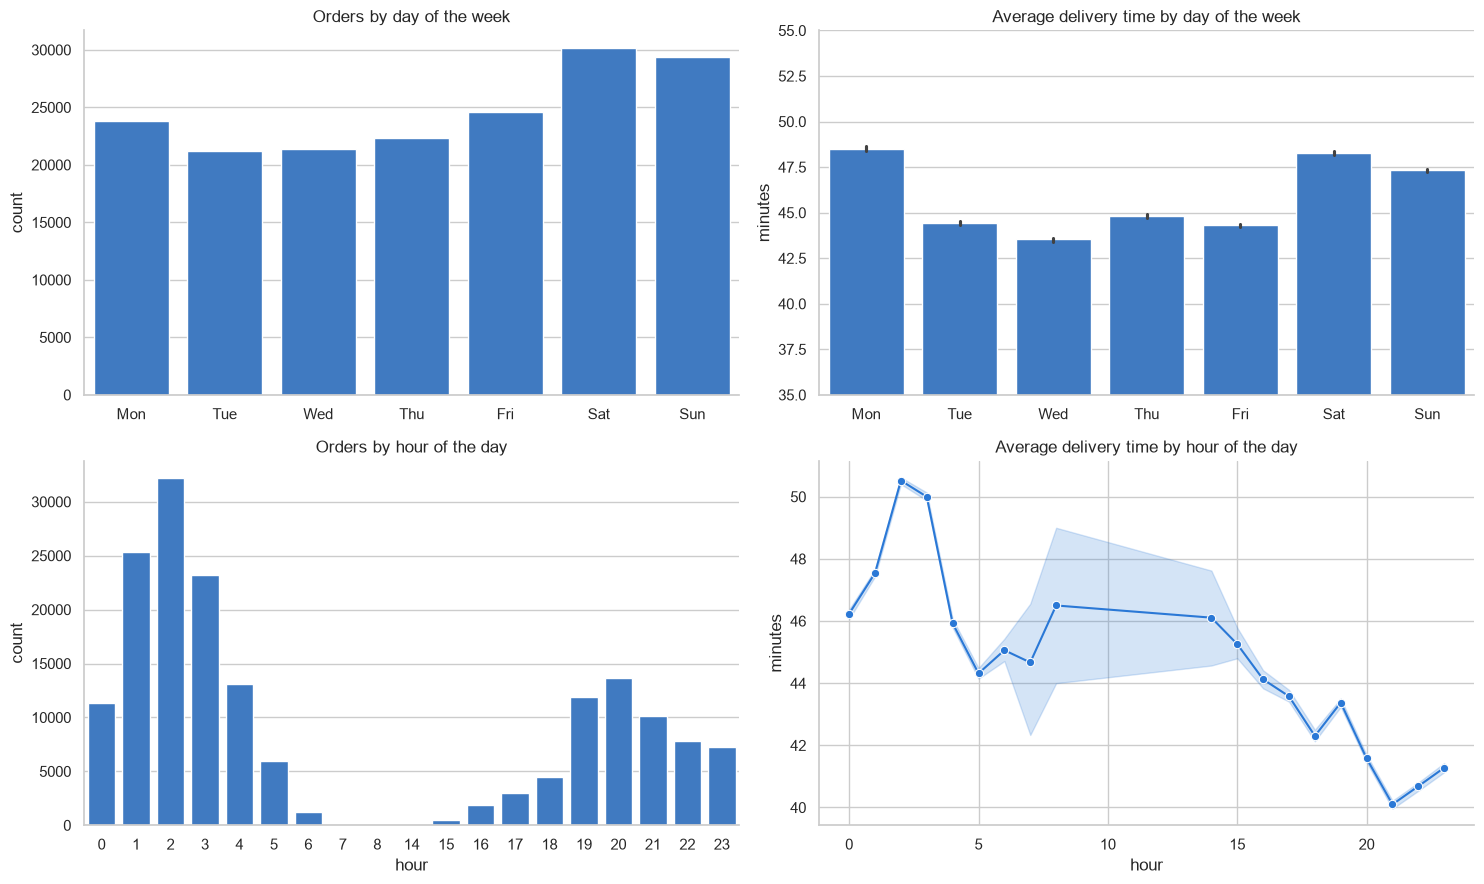

In [56]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

sns.countplot(data=df, x="day_of_week", color=BLUE, ax=axes[0, 0])
axes[0, 0].set_xticks(range(7))
axes[0, 0].set_xticklabels(day_names)
axes[0, 0].set_title("Orders by day of the week")
axes[0, 0].set_xlabel("")

sns.barplot(data=df, x="day_of_week", y="time_taken_mins", color=BLUE, errorbar=("ci", 95), n_boot=200, ax=axes[0, 1])
axes[0, 1].set_xticks(range(7))
axes[0, 1].set_xticklabels(day_names)
axes[0, 1].set_ylim(35, 55)
axes[0, 1].set_title("Average delivery time by day of the week")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("minutes")

sns.countplot(data=df, x="hour", color=BLUE, ax=axes[1, 0])
axes[1, 0].set_title("Orders by hour of the day")

sns.lineplot(data=df, x="hour", y="time_taken_mins", marker="o", color=BLUE, errorbar=("ci", 95), n_boot=200, ax=axes[1, 1])
axes[1, 1].set_title("Average delivery time by hour of the day")
axes[1, 1].set_ylabel("minutes")

plt.tight_layout()
plt.show()

In [57]:
print("Average delivery time by hour (minutes):")
print(df.groupby("hour")["time_taken_mins"].mean().round(1).to_string())
print("\nAverage delivery time by day of the week (minutes):")
print(df.groupby("day_of_week")["time_taken_mins"].mean().round(1).rename(dict(enumerate(day_names))).to_string())

Average delivery time by hour (minutes):
hour
0     46.2
1     47.5
2     50.5
3     50.0
4     45.9
5     44.3
6     45.1
7     44.7
8     46.5
14    46.1
15    45.3
16    44.1
17    43.6
18    42.3
19    43.4
20    41.6
21    40.1
22    40.7
23    41.3

Average delivery time by day of the week (minutes):
day_of_week
Mon    48.5
Tue    44.4
Wed    43.5
Thu    44.8
Fri    44.3
Sat    48.3
Sun    47.3


From the charts, orders are not spread evenly over the day. Almost all orders are placed between hours 0 and 4 and between hours 19 and 23 (as recorded in the file), and hours 6 to 15 have very few orders (hours 9 to 13 have none), which is why the line for those hours has a wide band. Delivery takes longest for orders placed at hours 2 and 3 (about 50 minutes) and shortest at hour 21 (40.1 minutes), a difference of about 10 minutes.

Saturdays and Sundays have the most orders (about 30,000 each), and Mondays (48.5 minutes) and Saturdays (48.3) are the slowest days, while Wednesdays (43.5) are the fastest. So the time of the order does affect delivery time, and `hour` and `day_of_week` are worth keeping as features.

## Section 3 Summary: Objective and How It Was Addressed

**Motto of this section:** *Look at the data, find what does not belong, and check that removing it helped.*

| Task | Where it is addressed | Result |
|:--|:--|:--|
| **Task 3.1:** correlation heatmap and scatterplots | **3.1**: countplots, histograms, correlation heatmap, scatterplots (time vs subtotal, items vs subtotal), box plots | Delivery time relates most to subtotal (0.41), orders waiting (0.39) and hour (-0.35) |
| **Task 3.2 and Question 4:** why check for outliers | **3.2** | Extreme values pull averages, scalers and squared errors |
| **Task 3.3 and Question 5:** three methods | **3.3**: IQR rule, z-score, Isolation Forest, the visual box plot and scatterplot, and a table of how many rows each would flag | IQR would flag 20.7% of rows, z-score 6.4%, Isolation Forest 1.0%; Isolation Forest chosen |
| **Task 3.4:** detect, print and remove | **3.4**: Isolation Forest on eight numeric columns (1,749 rows), then a 99.9th-percentile rule on `total_items` (174 rows) | 172,914 rows left (1.1% removed) |
| **Task 3.5:** re-plot and compare | **3.5**: same scatterplots and box plots, before and after, plus a table | Largest items 411 to 21, largest subtotal 26,800 to 18,920 |
| **Task 3.6:** volume and delivery time by day and hour | **3.6**: countplots and line plots with 95% bands | Orders cluster at hours 0 to 4 and 19 to 23; delivery is slowest at hours 2 to 3 and fastest at hour 21 |

**Limitation to remember:** the outlier rules were worked out on all rows before the split, so they saw rows that later became test rows (only input columns were used, never the target).